In [37]:
# Import Pandas for log data handling
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import OS for file and folder operations
import os

# Import Regex for log text processing
import re

# Import Matplotlib and Seaborn for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import TF-IDF for converting log text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Import supervised and unsupervised ML models
from sklearn.ensemble import (
    IsolationForest,
    RandomForestClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Import train-test split
from sklearn.model_selection import train_test_split

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

# Display all columns in DataFrames
pd.set_option("display.max_columns", None)

print("OpsMind AI - Log Anomaly Detection")
print("Libraries Imported Successfully!")

OpsMind AI - Log Anomaly Detection
Libraries Imported Successfully!


In [38]:

openstack_path = "../data/raw/logs/openstack"
hdfs_path = "../data/raw/logs/hdfs"

print("OpenStack Dataset Files:")
print(os.listdir(openstack_path))


print("\nHDFS Dataset Files:")
print(os.listdir(hdfs_path))

OpenStack Dataset Files:
['anomaly_labels.txt', 'openstack_abnormal.log', 'openstack_normal1.log', 'openstack_normal2.log']

HDFS Dataset Files:
['HDFS.log', 'preprocessed']


In [39]:
# Define paths for OpenStack log files
abnormal_file = os.path.join(openstack_path, "openstack_abnormal.log"
)

normal_file_1 = os.path.join( openstack_path, "openstack_normal1.log"
)

normal_file_2 = os.path.join( openstack_path, "openstack_normal2.log"
)

# Function to read log files line by line
def read_log_file(file_path):
    with open(file_path, "r", encoding="utf-8", errors="replace") as file:
        return file.readlines()

# Load abnormal and normal logs separately
abnormal_logs = read_log_file(abnormal_file)
normal_logs_1 = read_log_file(normal_file_1)
normal_logs_2 = read_log_file(normal_file_2)

# Display number of log lines
print("Abnormal Log Lines:", len(abnormal_logs))
print("Normal Log 1 Lines:", len(normal_logs_1))
print("Normal Log 2 Lines:", len(normal_logs_2))

Abnormal Log Lines: 18434
Normal Log 1 Lines: 52312
Normal Log 2 Lines: 137074


In [40]:
# Display first five abnormal log entries
print("ABNORMAL LOG SAMPLES:\n")

for line in abnormal_logs[:5]:
    print(line.strip())

# Display first five normal log entries
print("\nNORMAL LOG SAMPLES:\n")

for line in normal_logs_1[:5]:
    print(line.strip())

ABNORMAL LOG SAMPLES:

nova-api.log.2017-05-14_21:27:04 2017-05-14 19:39:01.445 25746 INFO nova.osapi_compute.wsgi.server [req-5a2050e7-b381-4ae9-92d2-8b08e9f9f4c0 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 "GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1" status: 200 len: 1583 time: 0.1919448
nova-api.log.2017-05-14_21:27:04 2017-05-14 19:39:01.650 25746 INFO nova.osapi_compute.wsgi.server [req-c26a7d54-55ab-412e-947f-421a2cb934fc 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 "GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/3edec1e4-9678-4a3a-a21b-a145a4ee5e61 HTTP/1.1" status: 200 len: 1708 time: 0.2011580
nova-compute.log.2017-05-14_21:27:09 2017-05-14 19:39:02.007 2931 INFO nova.virt.libvirt.driver [req-e285b551-587f-4c1d-8eba-dceb2673637f 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] [instance: 3edec1e4-9678-4a3a-a21b-a145a4ee5e61] Creating image
nova-api.log

In [41]:
# Combine both normal log files into one list
normal_logs = normal_logs_1 + normal_logs_2

# Create a DataFrame for normal log entries
normal_df = pd.DataFrame({
    "log": [line.strip() for line in normal_logs],
    "label": 0  # 0 represents normal logs
})

# Create a DataFrame for abnormal log entries
abnormal_df = pd.DataFrame({
    "log": [line.strip() for line in abnormal_logs],
    "label": 1  # 1 represents abnormal logs
})

# Combine normal and abnormal records
logs_df = pd.concat(
    [normal_df, abnormal_df],
    ignore_index=True
)

# Remove empty log entries
logs_df = logs_df[logs_df["log"] != ""].copy()

# Display dataset information
print("Combined Dataset Shape:", logs_df.shape)
print("\nLabel Distribution:")
print(logs_df["label"].value_counts())

# Display sample records
logs_df.head()

Combined Dataset Shape: (207820, 2)

Label Distribution:
label
0    189386
1     18434
Name: count, dtype: int64


,log,label
0,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
1,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
2,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
3,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
4,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0


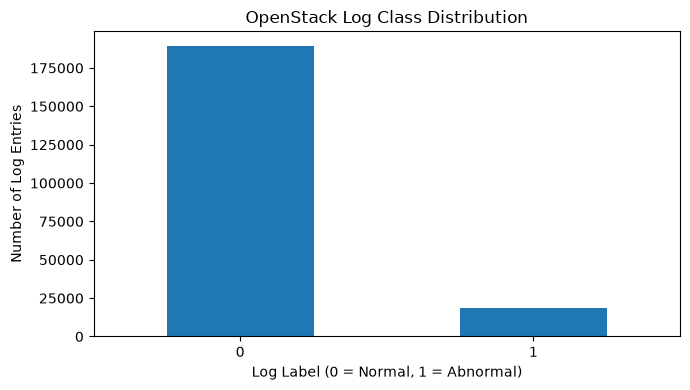

In [42]:
# Count normal and abnormal log entries
label_counts = logs_df["label"].value_counts().sort_index()

# Plot the class distribution
label_counts.plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("OpenStack Log Class Distribution")
plt.xlabel("Log Label (0 = Normal, 1 = Abnormal)")
plt.ylabel("Number of Log Entries")
plt.tight_layout()
plt.show()

In [43]:
# Create a copy to preserve the original combined dataset
processed_logs_df = logs_df.copy()

# Remove leading and trailing whitespace from log messages
processed_logs_df["log"] = (
    processed_logs_df["log"]
    .astype(str)
    .str.strip()
)

# Remove empty log messages
processed_logs_df = processed_logs_df[
    processed_logs_df["log"].str.len() > 0
].copy()

# Reset DataFrame index after cleaning
processed_logs_df.reset_index(drop=True, inplace=True)

# Display dataset quality information
print("Processed Dataset Shape:", processed_logs_df.shape)
print("Missing Values:", processed_logs_df.isnull().sum().sum())
print("Duplicate Rows:", processed_logs_df.duplicated().sum())

# Display cleaned log samples
processed_logs_df.head()

C:\Users\ishu1\AppData\Local\Temp\ipykernel_2144\3152448813.py:17: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  processed_logs_df.reset_index(drop=True, inplace=True)


Processed Dataset Shape: (207820, 2)
Missing Values: 0
Duplicate Rows: 0


,log,label
0,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
1,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
2,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
3,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0
4,nova-api.log.1.2017-05-16_13:53:08 2017-05-16 ...,0


In [44]:
# Import train-test splitting utility
from sklearn.model_selection import train_test_split

# Separate log messages and actual labels
X = processed_logs_df["log"]
y = processed_logs_df["label"]

# Split data while preserving normal/abnormal proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing dataset sizes
print("Training Logs:", len(X_train))
print("Testing Logs:", len(X_test))

# Display abnormal log counts in both sets
print("\nTraining Label Distribution:")
print(y_train.value_counts())

print("\nTesting Label Distribution:")
print(y_test.value_counts())

Training Logs: 166256
Testing Logs: 41564

Training Label Distribution:
label
0    151509
1     14747
Name: count, dtype: int64

Testing Label Distribution:
label
0    37877
1     3687
Name: count, dtype: int64


In [45]:
# Import TF-IDF vectorizer for text feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,  # Limit vocabulary size
    ngram_range=(1, 2),  # Extract single words and word pairs
    min_df=2,            # Ignore very rare terms
    max_df=0.95          # Ignore extremely common terms
)

# Learn vocabulary only from training logs
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test logs using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display extracted feature dimensions
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("TF-IDF Feature Extraction Completed!")

Training TF-IDF Shape: (166256, 10000)
Testing TF-IDF Shape: (41564, 10000)
TF-IDF Feature Extraction Completed!


In [46]:
# Save the cleaned OpenStack log dataset
processed_logs_df.to_csv(
    "../data/processed/openstack_processed_logs.csv",
    index=False
)

print("Processed OpenStack Logs Saved Successfully!")

Processed OpenStack Logs Saved Successfully!


In [47]:

# Create four models for comparison
models = {
    "Isolation Forest": IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

# Store model evaluation results
model_results = []

# Train and evaluate all four models
for name, classifier in models.items():

    print(f"\nTraining {name}...")

    # Train supervised models using actual labels
    if name != "Isolation Forest":
        classifier.fit(X_train_tfidf, y_train)

        # Generate predictions and anomaly scores
        predictions = classifier.predict(X_test_tfidf)

        if hasattr(classifier, "predict_proba"):
            scores = classifier.predict_proba(X_test_tfidf)[:, 1]
        else:
            scores = classifier.decision_function(X_test_tfidf)

    else:
        # Train Isolation Forest without using training labels
        classifier.fit(X_train_tfidf)

        # Isolation Forest: -1 means anomaly, 1 means normal
        raw_predictions = classifier.predict(X_test_tfidf)

        # Convert anomaly predictions into 1 and normal into 0
        predictions = (raw_predictions == -1).astype(int)

        # Higher score should indicate greater anomaly likelihood
        scores = -classifier.decision_function(X_test_tfidf)

    # Calculate evaluation metrics
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test, scores)
    })

    print(f"{name} Training and Evaluation Completed!")

# Create a comparison table
comparison_df = pd.DataFrame(model_results)

# Sort models by abnormal-class F1 score
comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display final comparison
comparison_df


Training Isolation Forest...
Isolation Forest Training and Evaluation Completed!

Training Random Forest...
Random Forest Training and Evaluation Completed!

Training Logistic Regression...
Logistic Regression Training and Evaluation Completed!

Training Linear SVM...
Linear SVM Training and Evaluation Completed!


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,1.000000,1.0,1.0,1.0,1.00000
1,Logistic Regression,1.000000,1.0,1.0,1.0,1.00000
2,Linear SVM,1.000000,1.0,1.0,1.0,1.00000
3,Isolation Forest,0.911293,0.0,0.0,0.0,0.16527


In [48]:
# Convert training and testing logs into sets
# This helps identify identical log messages in both datasets

train_log_set = set(X_train)
test_log_set = set(X_test)

# Find exact log messages appearing in both sets
overlapping_logs = train_log_set.intersection(test_log_set)

# Calculate overlap statistics
print("Unique Training Logs:", len(train_log_set))
print("Unique Testing Logs:", len(test_log_set))
print("Exact Overlapping Logs:", len(overlapping_logs))

# Calculate percentage of test logs already seen in training
overlap_percentage = (
    len(overlapping_logs) / len(test_log_set)
) * 100

print("Test Log Overlap Percentage:", round(overlap_percentage, 2), "%")

Unique Training Logs: 166256
Unique Testing Logs: 41564
Exact Overlapping Logs: 0
Test Log Overlap Percentage: 0.0 %


In [49]:
# Check whether identical log messages have conflicting labels
label_conflicts = (
    processed_logs_df.groupby("log")["label"]
    .nunique()
)

# Count log messages associated with both normal and abnormal labels
conflict_count = (label_conflicts > 1).sum()

print("Log Patterns With Conflicting Labels:", conflict_count)

# Display exact duplicate counts for each label
print("\nDuplicate Log Counts by Label:")
print(
    processed_logs_df.groupby("label")["log"]
    .agg(["count", "nunique"])
)

Log Patterns With Conflicting Labels: 0

Duplicate Log Counts by Label:
        count  nunique
label                 
0      189386   189386
1       18434    18434


In [50]:
# Create a copy of the original dataset
clean_logs_df = processed_logs_df.copy()

# Remove source filename, date, time and process ID
# Keep log severity and actual message for learning
def remove_log_metadata(log):

    # Split log entry into individual fields
    parts = str(log).split()

    # Remove first four metadata fields when available
    if len(parts) > 4:
        return " ".join(parts[4:])

    # Return original text if format is shorter
    return str(log)

# Apply metadata removal to every log entry
clean_logs_df["log"] = clean_logs_df["log"].apply(
    remove_log_metadata
)

# Display original and cleaned log samples
print("Original Log:")
print(processed_logs_df["log"].iloc[0])

print("\nCleaned Log:")
print(clean_logs_df["log"].iloc[0])

# Display dataset shape
print("\nClean Dataset Shape:", clean_logs_df.shape)

Original Log:
nova-api.log.1.2017-05-16_13:53:08 2017-05-16 00:00:00.008 25746 INFO nova.osapi_compute.wsgi.server [req-38101a0b-2096-447d-96ea-a692162415ae 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 "GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1" status: 200 len: 1893 time: 0.2477829

Cleaned Log:
INFO nova.osapi_compute.wsgi.server [req-38101a0b-2096-447d-96ea-a692162415ae 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 "GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1" status: 200 len: 1893 time: 0.2477829

Clean Dataset Shape: (207820, 2)


In [51]:
# Separate cleaned log messages and their labels
X_clean = clean_logs_df["log"]
y_clean = clean_logs_df["label"]

# Split cleaned data into training and testing sets
# Stratification maintains the normal/abnormal ratio
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

# Display the new dataset sizes
print("Training Samples:", len(X_train_clean))
print("Testing Samples:", len(X_test_clean))

# Display class distribution
print("\nTraining Distribution:")
print(y_train_clean.value_counts())

print("\nTesting Distribution:")
print(y_test_clean.value_counts())

Training Samples: 166256
Testing Samples: 41564

Training Distribution:
label
0    151509
1     14747
Name: count, dtype: int64

Testing Distribution:
label
0    37877
1     3687
Name: count, dtype: int64


In [52]:
# Create a fresh TF-IDF vectorizer
# Learn vocabulary only from cleaned training logs
clean_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Fit vectorizer on training data
X_train_clean_tfidf = clean_tfidf.fit_transform(X_train_clean)

# Transform testing data using the same vocabulary
X_test_clean_tfidf = clean_tfidf.transform(X_test_clean)

# Display feature dimensions
print("Training TF-IDF Shape:", X_train_clean_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_clean_tfidf.shape)

Training TF-IDF Shape: (166256, 10000)
Testing TF-IDF Shape: (41564, 10000)


In [53]:
# Define four models for cleaned log classification
clean_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),

    "Isolation Forest": IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
}

# Store evaluation results
clean_results = []

# Train and evaluate all four models
for name, classifier in clean_models.items():

    print(f"\nTraining {name}...")

    # Train supervised models with actual labels
    if name != "Isolation Forest":
        classifier.fit(X_train_clean_tfidf, y_train_clean)

        predictions = classifier.predict(X_test_clean_tfidf)

        # Generate continuous scores for PR-AUC
        if hasattr(classifier, "predict_proba"):
            scores = classifier.predict_proba(X_test_clean_tfidf)[:, 1]
        else:
            scores = classifier.decision_function(X_test_clean_tfidf)

    else:
        # Train unsupervised anomaly detection model
        classifier.fit(X_train_clean_tfidf)

        # Convert -1 anomaly predictions into label 1
        raw_predictions = classifier.predict(X_test_clean_tfidf)
        predictions = (raw_predictions == -1).astype(int)

        # Higher score represents greater anomaly likelihood
        scores = -classifier.decision_function(X_test_clean_tfidf)

    # Calculate evaluation metrics
    clean_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_clean, predictions),
        "Precision": precision_score(y_test_clean, predictions, zero_division=0),
        "Recall": recall_score(y_test_clean, predictions, zero_division=0),
        "F1 Score": f1_score(y_test_clean, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test_clean, scores)
    })

    print(f"{name} Completed!")

# Create and sort the comparison table
clean_comparison_df = pd.DataFrame(clean_results)

clean_comparison_df = clean_comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display final comparison
clean_comparison_df


Training Random Forest...
Random Forest Completed!

Training Logistic Regression...
Logistic Regression Completed!

Training Linear SVM...
Linear SVM Completed!

Training Isolation Forest...
Isolation Forest Completed!


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.823621,0.275450,0.606184,0.378781,0.524339
1,Linear SVM,0.803893,0.254022,0.625170,0.361257,0.495308
2,Random Forest,0.850592,0.287662,0.463520,0.355006,0.321837
3,Isolation Forest,0.911293,0.000000,0.000000,0.000000,0.091028


In [54]:
# Import threshold evaluation metrics
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Get prediction scores from trained Logistic Regression
y_scores = best_clean_model.decision_function(
    X_test_clean_tfidf
)

# Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_test_clean,
    y_scores
)

# Calculate F1 scores
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

# Find threshold with maximum F1 score
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Best Precision:", precisions[best_index])
print("Best Recall:", recalls[best_index])
print("Best F1 Score:", f1_scores[best_index])

# Generate predictions using optimized threshold
optimized_predictions = (
    y_scores >= best_threshold
).astype(int)

print("\nOptimized Classification Report:")

print(classification_report(
    y_test_clean,
    optimized_predictions,
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

Best Threshold: 1.0958198881562584
Best Precision: 0.7125803489439853
Best Recall: 0.42093843232980743
Best F1 Score: 0.52924126167539

Optimized Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96     37877
    Abnormal       0.71      0.42      0.53      3687

    accuracy                           0.93     41564
   macro avg       0.83      0.70      0.75     41564
weighted avg       0.93      0.93      0.93     41564



In [55]:
# AGAIN TRAINING AND EVALUATION

# 1. Split training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_clean,
    y_train_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_train_clean
)

# 2. Fit TF-IDF only on subtraining data
final_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_subtrain_tfidf = final_tfidf.fit_transform(X_subtrain)
X_val_tfidf = final_tfidf.transform(X_val)
X_final_test_tfidf = final_tfidf.transform(X_test_clean)

# 3. Train supervised Logistic Regression
lr_final = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_final.fit(X_subtrain_tfidf, y_subtrain)

# 4. Train Isolation Forest using only normal training logs
normal_training_data = X_subtrain_tfidf[
    (y_subtrain == 0).values
]

if_final = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

if_final.fit(normal_training_data)

# 5. Function to select threshold using validation data only
def select_threshold(y_true, scores):

    precision, recall, thresholds = precision_recall_curve(
        y_true, scores
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_values)

    return thresholds[best_index]

# 6. Get validation scores
lr_val_scores = lr_final.decision_function(X_val_tfidf)

if_val_scores = -if_final.decision_function(X_val_tfidf)

# Select thresholds on validation data
lr_threshold = select_threshold(y_val, lr_val_scores)
if_threshold = select_threshold(y_val, if_val_scores)

print("Logistic Regression Threshold:", lr_threshold)
print("Isolation Forest Threshold:", if_threshold)

# 7. Evaluate both models on untouched test data
lr_test_scores = lr_final.decision_function(
    X_final_test_tfidf
)

if_test_scores = -if_final.decision_function(
    X_final_test_tfidf
)

lr_predictions = (lr_test_scores >= lr_threshold).astype(int)
if_predictions = (if_test_scores >= if_threshold).astype(int)

# 8. Generate final comparison
final_results = []

for name, predictions, scores in [
    ("Logistic Regression", lr_predictions, lr_test_scores),
    ("Isolation Forest", if_predictions, if_test_scores)
]:

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_clean, predictions),
        "Precision": precision_score(y_test_clean, predictions, zero_division=0),
        "Recall": recall_score(y_test_clean, predictions, zero_division=0),
        "F1 Score": f1_score(y_test_clean, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test_clean, scores)
    })

final_comparison = pd.DataFrame(final_results)

final_comparison = final_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
final_comparison

Logistic Regression Threshold: 0.9500736046886544
Isolation Forest Threshold: -0.1949192012592736

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.931455,0.692202,0.409276,0.514403,0.516226
1,Isolation Forest,0.090222,0.088564,0.996203,0.162666,0.081835


In [56]:
# Import joblib for saving trained models
import joblib
import os

# Create final model package
final_model_package = {
    "model": lr_final,
    "vectorizer": final_tfidf,
    "threshold": lr_threshold,
    "model_name": "Logistic Regression",
    "target_classes": {
        0: "Normal",
        1: "Abnormal"
    }
}

# Define model save location
model_path = "../data/processed/best_log_anomaly_model.pkl"

# Save the complete model package
joblib.dump(
    final_model_package,
    model_path
)

print("Final Log Anomaly Model Saved Successfully!")
print("Model Path:", model_path)
print("Selected Model: Logistic Regression")
print("Validation Threshold:", lr_threshold)

Final Log Anomaly Model Saved Successfully!
Model Path: ../data/processed/best_log_anomaly_model.pkl
Selected Model: Logistic Regression
Validation Threshold: 0.9500736046886544


In [57]:
# Load the saved model package
loaded_package = joblib.load(
    "../data/processed/best_log_anomaly_model.pkl"
)

# Extract trained components
loaded_model = loaded_package["model"]
loaded_vectorizer = loaded_package["vectorizer"]
loaded_threshold = loaded_package["threshold"]

# Prepare sample logs
sample_logs = [
    "INFO nova.osapi_compute.wsgi.server request completed successfully",
    "ERROR nova.compute manager failed to create virtual machine",
    "WARNING network connection timeout while processing request"
]

# Convert sample logs into TF-IDF features
sample_features = loaded_vectorizer.transform(sample_logs)

# Predict anomaly scores
sample_scores = loaded_model.decision_function(sample_features)

# Apply saved threshold
sample_predictions = (
    sample_scores >= loaded_threshold
).astype(int)

# Display prediction results
for log, prediction in zip(sample_logs, sample_predictions):

    label = "ABNORMAL" if prediction == 1 else "NORMAL"

    print("Log:", log)
    print("Prediction:", label)
    print("-" * 70)

Log: INFO nova.osapi_compute.wsgi.server request completed successfully
Prediction: NORMAL
----------------------------------------------------------------------
Log: ERROR nova.compute manager failed to create virtual machine
Prediction: NORMAL
----------------------------------------------------------------------
Log: WARNING network connection timeout while processing request
Prediction: NORMAL
----------------------------------------------------------------------
